# Monitor the live AQI


In [1]:
import json

from vayuayan import (
    CPCBLive,
    get_aqi_category,
    health_impact,
    live_metrics,
    set_theme,
)

set_theme()

## 1. Get your location


In [2]:
client = CPCBLive()

lat, lon = client.get_system_location()
# IP geolocation is approximate, so 1 decimal (about 11 km) is enough
print(f"Your approximate location: {lat:.1f}, {lon:.1f}")

Your approximate location: 19.1, 72.9


## 2. Find the nearest monitoring station


In [3]:
nearest_station = client.get_nearest_station()
print("Nearest Monitoring Station:")

station_id = nearest_station[0]
station_name = nearest_station[1]
print(f"\nMonitoring Station ID: {station_id}")
print(f"Station Name: {station_name}")

Nearest Monitoring Station:

Monitoring Station ID: site_5104
Station Name: Kurla, Mumbai - MPCB


## 3. Get the current air quality data


In [4]:
aqi_data = client.get_live_aqi_data(station_id=station_id)

print(f"Current Air Quality at {station_name}:")
metrics = live_metrics(aqi_data)
if metrics.empty:
    print("No data available, possibly due to station being offline.")
else:
    print(metrics.to_string(index=False, na_rep="NA"))

Current Air Quality at Kurla, Mumbai - MPCB:


pollutant  avg  min  max              period
    PM2.5   NA   NA   NA 01-11-2026 19:00:00
     PM10   NA   NA   NA 01-11-2026 19:00:00
      NO2   NA   NA   NA 01-11-2026 19:00:00
      NH3   NA   NA   NA 01-11-2026 19:00:00
      SO2   NA   NA   NA 01-11-2026 19:00:00
       CO   NA   NA   NA 01-11-2026 19:00:00
    OZONE 28.0 28.0 29.0 01-11-2026 19:00:00


## 4. Get the recent 15-minute history

The live feed gives only the newest reading. To get a time series, download the
15-minute raw data of the station with `CPCBHistorical`. The code that follows
plots the PM2.5 and PM10 of the last 3 days for the station that you found above.

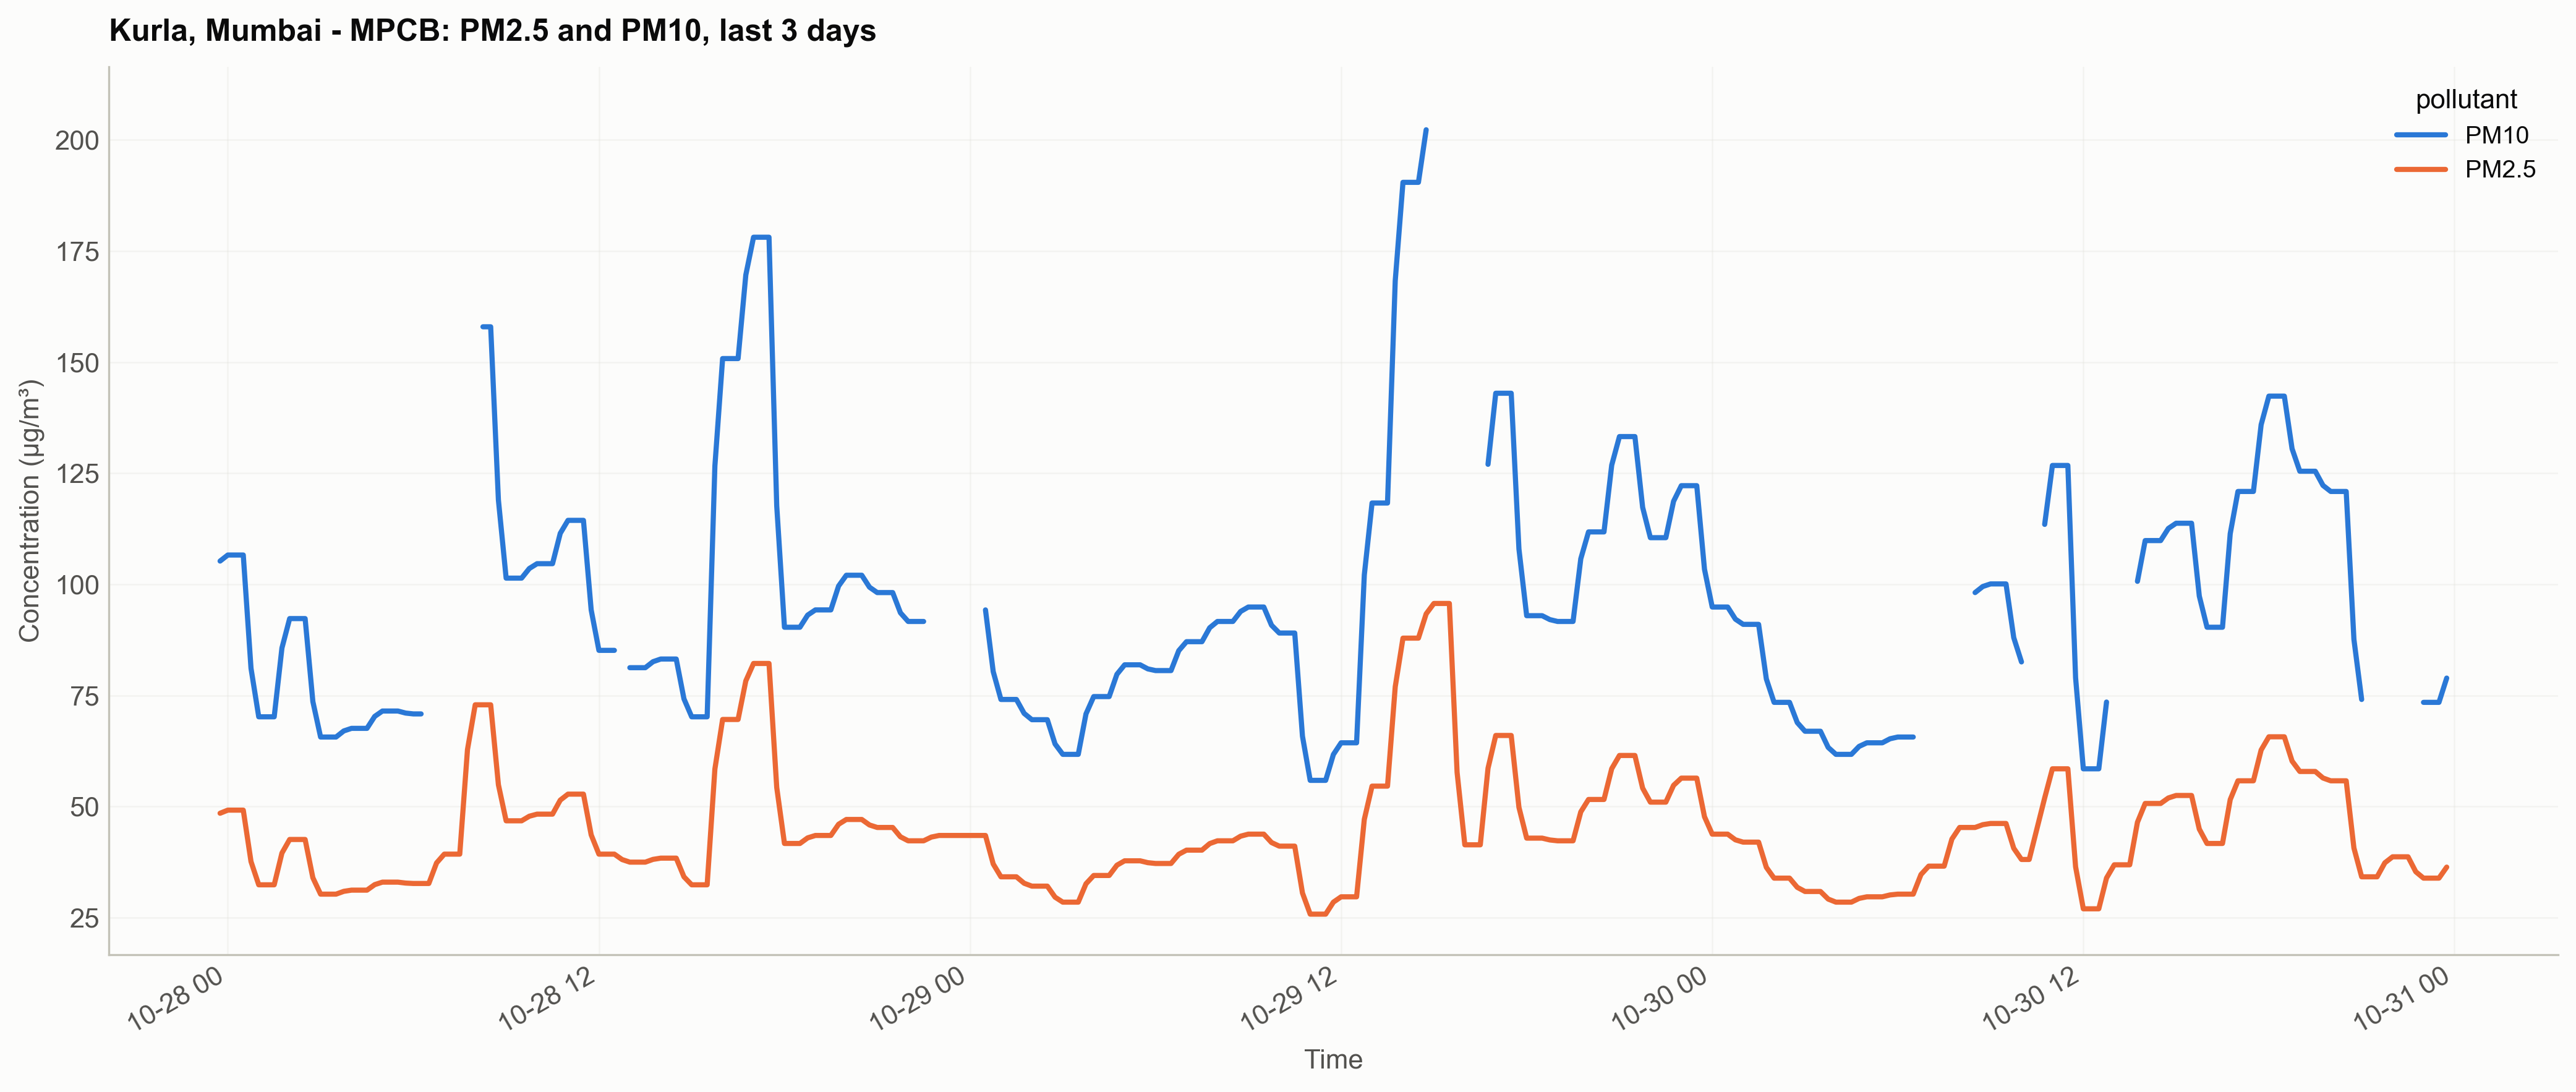

            min    max  mean
pollutant                   
PM10       55.9  207.4  96.5
PM2.5      25.8   95.7  44.6


In [5]:
import matplotlib.pyplot as plt
import pandas as pd

from vayuayan import CPCBHistorical

history = CPCBHistorical()
raw = history.download_raw_aqi_data_station_level(station_id, "2026", "", tidy=True)

# The window ends at the newest reading that CPCB has published
pm = raw[raw["pollutant"].isin(["PM2.5", "PM10"])]
window_start = raw["timestamp"].max() - pd.Timedelta(days=3)
recent = pm[pm["timestamp"] >= window_start]

if recent.empty:
    print("No recent 15-minute data for this station.")
else:
    series = recent.pivot(index="timestamp", columns="pollutant", values="value")
    ax = series.plot(figsize=(14, 6))
    ax.set_title(f"{station_name}: PM2.5 and PM10, last 3 days")
    ax.set_xlabel("Time")
    ax.set_ylabel("Concentration (µg/m³)")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print(recent.groupby("pollutant")["value"].agg(["min", "max", "mean"]).round(1))

## 5. Find the AQI category and health effect

In [6]:
aqi_value = (aqi_data.get("aqi") or aqi_data.get("airQualityIndex") or {}).get("value")

if aqi_value is None:
    print("The current AQI is not available.")
else:
    aqi_value = float(aqi_value)
    print(f"Current AQI: {aqi_value:.0f}")
    print(f"Category: {get_aqi_category(aqi_value)}")
    print(f"Possible health impact: {health_impact(aqi_value)}")

The current AQI is not available.


## 6. Get the AQI for specific coordinates


In [7]:
mumbai_lat = 19.0760
mumbai_lon = 72.8777

coords = (mumbai_lat, mumbai_lon)

mumbai_station = client.get_nearest_station(coords=coords)
print("Nearest station to Mumbai:")
print(json.dumps(mumbai_station, indent=2))

mumbai_aqi = client.get_live_aqi_data(coords=coords)
mumbai_aqi.pop("last_hours", None)  # Makes the output shorter
print("\nCurrent AQI in Mumbai:")
print(json.dumps(mumbai_aqi, indent=2))

Nearest station to Mumbai:
[
  "site_5104",
  "Kurla, Mumbai - MPCB"
]

Current AQI in Mumbai:
{
  "station_id": "site_5104",
  "station_name": "Kurla, Mumbai - MPCB",
  "lastUpdate": "01-11-2026 19:00:00",
  "airQualityIndex": {
    "value": null
  },
  "metrics": [
    {
      "name": "PM2.5",
      "avg": "NA",
      "min": "NA",
      "max": "NA",
      "avgDesc": "01-11-2026 19:00:00"
    },
    {
      "name": "PM10",
      "avg": "NA",
      "min": "NA",
      "max": "NA",
      "avgDesc": "01-11-2026 19:00:00"
    },
    {
      "name": "NO2",
      "avg": "NA",
      "min": "NA",
      "max": "NA",
      "avgDesc": "01-11-2026 19:00:00"
    },
    {
      "name": "NH3",
      "avg": "NA",
      "min": "NA",
      "max": "NA",
      "avgDesc": "01-11-2026 19:00:00"
    },
    {
      "name": "SO2",
      "avg": "NA",
      "min": "NA",
      "max": "NA",
      "avgDesc": "01-11-2026 19:00:00"
    },
    {
      "name": "CO",
      "avg": "NA",
      "min": "NA",
      "max": "N